Retail Sales Dataset

This dataset contains retail sales transaction information. Each row represents a single transaction. It includes information about the transaction, customer, product category, quantity purchased, price per unit, and total amount.

The dataset contains 1,000 transactions and 9 columns. The main objective of this analysis is to clean the dataset and perform Exploratory Data Analysis (EDA) to understand sales patterns, customer characteristics, product categories, and purchasing behavior.

I am using Pandas for data manipulation and analysis, Matplotlib and Seaborn for data visualization.


In [45]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

loaded the Excel file and stored it in a DataFrame called df.

In [46]:
df = pd.read_excel('/content/retail_sales_datasetexcel.xlsx')
df

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100
...,...,...,...,...,...,...,...,...,...
995,996,2023-05-16,CUST996,Male,62,Clothing,1,50,50
996,997,2023-11-17,CUST997,Male,52,Beauty,3,30,90
997,998,2023-10-29,CUST998,Female,23,Beauty,4,25,100
998,999,2023-12-05,CUST999,Female,36,Electronics,3,50,150


Used head() to see the first few records


In [47]:
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


Used tail() to see the last few records

In [48]:
df.tail()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
995,996,2023-05-16,CUST996,Male,62,Clothing,1,50,50
996,997,2023-11-17,CUST997,Male,52,Beauty,3,30,90
997,998,2023-10-29,CUST998,Female,23,Beauty,4,25,100
998,999,2023-12-05,CUST999,Female,36,Electronics,3,50,150
999,1000,2023-04-12,CUST1000,Male,47,Electronics,4,30,120


the shape of the dataset

In [49]:
df.shape

(1000, 9)

the data types of each column

In [50]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction ID    1000 non-null   int64         
 1   Date              1000 non-null   datetime64[ns]
 2   Customer ID       1000 non-null   object        
 3   Gender            1000 non-null   object        
 4   Age               1000 non-null   int64         
 5   Product Category  1000 non-null   object        
 6   Quantity          1000 non-null   int64         
 7   Price per Unit    1000 non-null   int64         
 8   Total Amount      1000 non-null   int64         
dtypes: datetime64[ns](1), int64(5), object(3)
memory usage: 70.4+ KB


Summary statistics

In [51]:
df.describe()

,Transaction ID,Date,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,2023-07-03 00:25:55.200000256,41.39200,2.514000,179.890000,456.000000
min,1.000000,2023-01-01 00:00:00,18.00000,1.000000,25.000000,25.000000
25%,250.750000,2023-04-08 00:00:00,29.00000,1.000000,30.000000,60.000000
50%,500.500000,2023-06-29 12:00:00,42.00000,3.000000,50.000000,135.000000
75%,750.250000,2023-10-04 00:00:00,53.00000,4.000000,300.000000,900.000000
max,1000.000000,2024-01-01 00:00:00,64.00000,4.000000,500.000000,2000.000000
std,288.819436,NaN,13.68143,1.132734,189.681356,559.997632


checked for missing values

In [52]:
df.isnull().sum()

,0
Transaction ID,0
Date,0
Customer ID,0
Gender,0
Age,0
Product Category,0
Quantity,0
Price per Unit,0
Total Amount,0


checked whether there were any duplicate records

In [53]:
df.duplicated().sum()

np.int64(0)

Datatype checking


In [54]:
df.dtypes

,0
Transaction ID,int64
Date,datetime64[ns]
Customer ID,object
Gender,object
Age,int64
Product Category,object
Quantity,int64
Price per Unit,int64
Total Amount,int64


Unique values

In [55]:
df.nunique()

,0
Transaction ID,1000
Date,345
Customer ID,1000
Gender,2
Age,47
Product Category,3
Quantity,4
Price per Unit,5
Total Amount,18


distribution of customers

In [56]:
df["Gender"].value_counts()

,count
Gender,
Female,510
Male,490


Count plot, It counts how many transactions belong to each gender

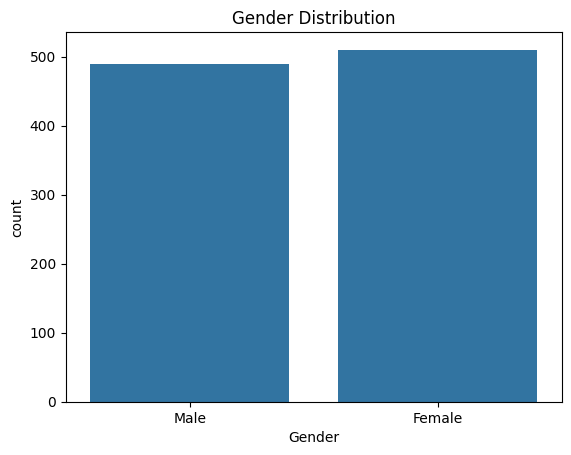

In [57]:
from numpy import number
sns.countplot(x="Gender",data=df)
plt.title("Gender Distribution")
plt.show()

Total amount for each category





In [58]:
df1 = df.groupby("Product Category")["Total Amount"].sum()
df1

,Total Amount
Product Category,
Beauty,143515
Clothing,155580
Electronics,156905


Pie plot

In [59]:
df3 = df.groupby("Product Category")["Quantity"].sum()
df3

,Quantity
Product Category,
Beauty,771
Clothing,894
Electronics,849


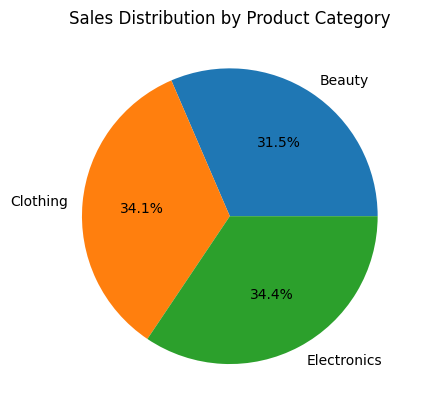

In [60]:
plt.pie(df1,labels=df1.index,autopct="%.1f%%")
plt.title("Sales Distribution by Product Category")
plt.show()

Customer Age Distribution

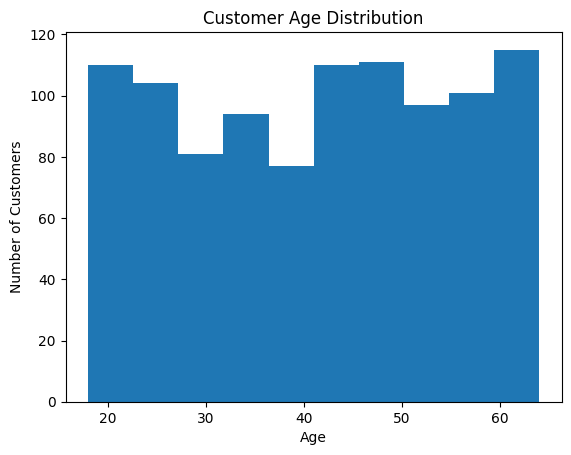

In [61]:
plt.hist(df["Age"], bins=10)
plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.show()

Relationship Between Quantity and Total Amount



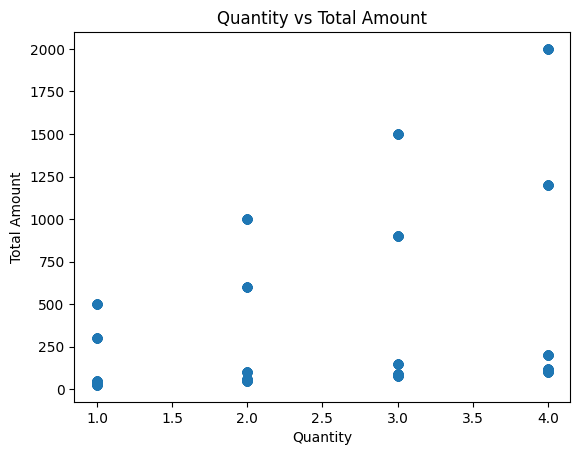

In [62]:
plt.scatter(df["Quantity"], df["Total Amount"])
plt.title("Quantity vs Total Amount")
plt.xlabel("Quantity")
plt.ylabel("Total Amount")
plt.show()

Outlier Analysis of Total Amount

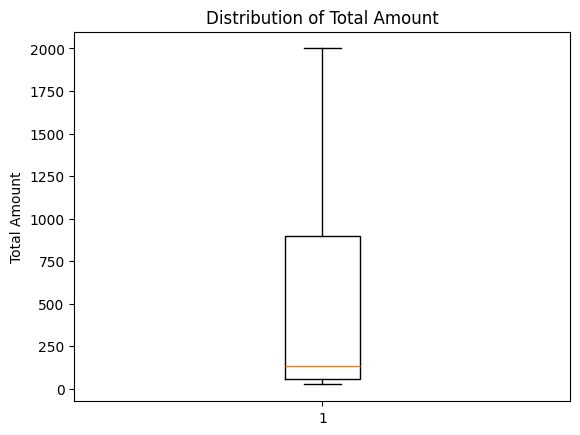

In [63]:
plt.boxplot(df["Total Amount"])
plt.title("Distribution of Total Amount")
plt.ylabel("Total Amount")
plt.show()

Correlation Heatmap

Line plot — Sales trend over time

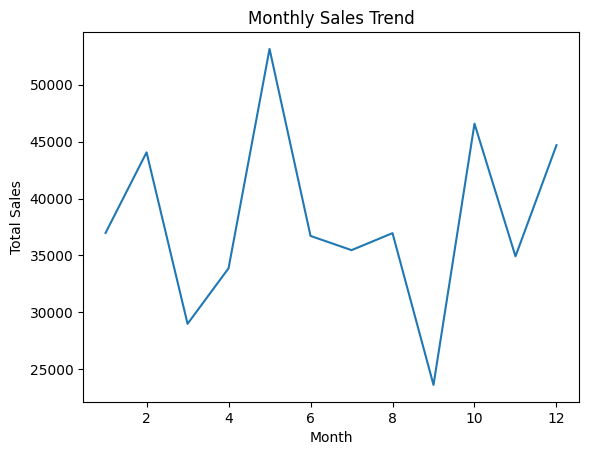

In [64]:
df4= df.groupby(df["Date"].dt.month)["Total Amount"].sum()
plt.plot(df4.index,df4.values)
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.show()

Heatmap — Correlation between numerical columns

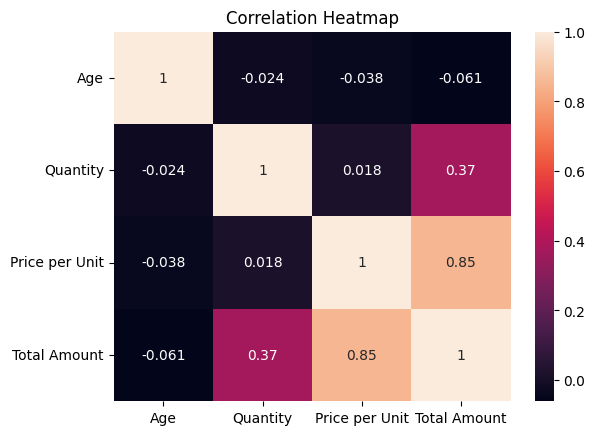

In [65]:
corr = df[["Age", "Quantity", "Price per Unit", "Total Amount"]].corr()
sns.heatmap(corr, annot=True)
plt.title("Correlation Heatmap")
plt.show()

Pairplot

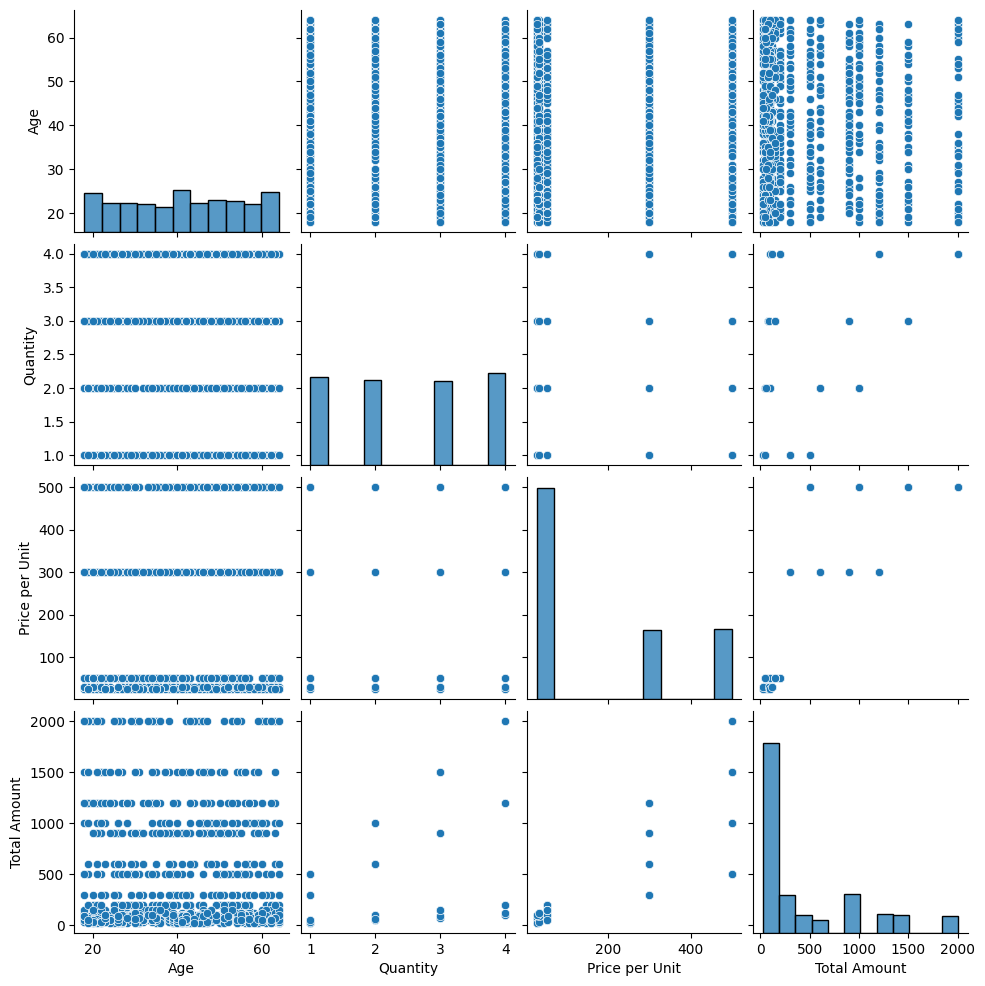

In [66]:
sns.pairplot(df[["Age", "Quantity", "Price per Unit", "Total Amount"]])
plt.show()

Insights:
The sales are fairly balanced across the three product categories, with Electronics contributing the highest total sales. Transactions are also almost equally distributed between male and female customers. Customers range from 18 to 64 years, with an average age of around 41 years. There is a moderate positive relationship between quantity and total amount, while price per unit has a strong positive relationship with total amount. Age has almost no relationship with spending. The boxplot shows some high-value transactions, and the monthly sales trend shows fluctuations rather than a consistent upward or downward trend.
